### Librerías

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Análisis de Integridad

In [2]:
df=pd.read_csv("reclamo_seguro_automotor.csv") # cargo el dataset

In [3]:
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [4]:
df.info() # en este punto verifico que el dataset, no contenga valores nulos en sus variables.

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  str    
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  str    
 8   model                             58592 non-null  str    
 9   fuel_type                         58592 non-null  str    
 10  max_torque                        58592 non-null  str    
 11  max_power                         58592 non-null  str    
 12  engine_type    

In [5]:
df.head(10) # realizo una inspección visual de los primeros 10 registros - No se observan anomalías

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
5,ID00006,1.018709,0.07,0.519231,C6,13051,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
6,ID00007,0.097992,0.16,0.403846,C7,6112,4,B2,M5,Diesel,...,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0
7,ID00008,0.509085,0.14,0.423077,C8,8794,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
8,ID00009,0.282394,0.07,0.298077,C7,6112,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
9,ID00010,0.566255,0.04,0.442308,C9,17804,1,B2,M7,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,0,0


In [6]:
df.tail(10) # inspección visual de los últimos 10 registros - No se observan anomalías

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
58582,ID58583,0.330476,0.11,0.432692,C2,27003,1,B2,M7,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,0,0
58583,ID58584,0.002870,0.03,0.288462,C14,7788,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
58584,ID58585,0.009512,0.00,0.307692,C13,5410,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
58585,ID58586,0.366244,0.09,0.557692,C8,8794,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
58586,ID58587,1.240162,0.07,0.461538,C3,4076,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58591,ID58592,0.124429,0.02,0.442308,C8,8794,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [7]:
df.sample(10, random_state=45) # inspección visual de 10 registros aleatorios, con una semilla de aleatoriedad de 45- No se observan anomalías

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
58070,ID58071,0.267098,0.18,0.461538,C12,34791,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
20348,ID20349,0.006780,0.00,0.423077,C9,17804,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
7422,ID07423,0.612607,0.00,0.576923,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
21805,ID21806,0.098812,0.01,0.461538,C10,73430,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
48318,ID48319,0.362131,0.13,0.442308,C3,4076,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
51413,ID51414,1.044692,0.15,0.413462,C13,5410,4,B2,M5,Diesel,...,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0
19682,ID19683,0.097891,0.03,0.346154,C2,27003,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
7538,ID07539,1.024822,0.00,0.576923,C7,6112,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
2184,ID02185,0.666004,0.16,0.365385,C5,34738,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
8139,ID08140,0.276818,0.15,0.423077,C2,27003,3,C2,M4,Diesel,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [8]:
df.describe() # analizo las variables numéricas

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,is_claim
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.00000,58592.000000,58592.000000,58592.000000
mean,0.611246,0.069424,0.469420,18826.858667,1.763722,3.137066,1162.355851,3.626963,5.245443,4.852893,3850.476891,1672.233667,1553.33537,1385.276813,1.759950,0.063968
std,0.414156,0.056721,0.122886,17660.174792,1.136988,1.832641,266.304786,0.483616,0.430353,0.228061,311.457119,112.089135,79.62227,212.423085,1.389576,0.244698
min,0.002735,0.000000,0.288462,290.000000,1.000000,1.000000,796.000000,3.000000,5.000000,4.500000,3445.000000,1475.000000,1475.00000,1051.000000,0.000000,0.000000
25%,0.210250,0.020000,0.365385,6112.000000,1.000000,2.000000,796.000000,3.000000,5.000000,4.600000,3445.000000,1515.000000,1475.00000,1185.000000,0.000000,0.000000
50%,0.573792,0.060000,0.451923,8794.000000,1.000000,2.000000,1197.000000,4.000000,5.000000,4.800000,3845.000000,1735.000000,1530.00000,1335.000000,2.000000,0.000000
75%,1.039104,0.110000,0.548077,27003.000000,3.000000,6.000000,1493.000000,4.000000,5.000000,5.000000,3995.000000,1755.000000,1635.00000,1510.000000,3.000000,0.000000
max,1.396641,1.000000,1.000000,73430.000000,5.000000,6.000000,1498.000000,4.000000,6.000000,5.200000,4300.000000,1811.000000,1825.00000,1720.000000,5.000000,1.000000


In [9]:
# la antigüedad del vehículo parece contener datos atípicos, ya que el valor máximo se encuentra muy alejado del promedio
# y de los cuartiles.

In [10]:
df.age_of_car.describe()

count    58592.000000
mean         0.069424
std          0.056721
min          0.000000
25%          0.020000
50%          0.060000
75%          0.110000
max          1.000000
Name: age_of_car, dtype: float64

In [11]:
df.age_of_car.unique()

array([0.05, 0.02, 0.11, 0.07, 0.16, 0.14, 0.04, 0.01, 0.12, 0.03, 0.1 ,
       0.09, 0.  , 0.08, 0.15, 0.13, 0.39, 0.17, 0.06, 0.18, 0.2 , 0.29,
       0.19, 0.38, 0.22, 0.23, 0.26, 0.21, 0.27, 0.28, 0.3 , 0.25, 0.31,
       0.33, 0.35, 0.32, 0.24, 0.37, 1.  , 0.42, 0.36, 0.45, 0.49, 0.46,
       0.34, 0.82, 0.44, 0.62, 0.81])

In [12]:
df.age_of_car.info()

<class 'pandas.Series'>
RangeIndex: 58592 entries, 0 to 58591
Series name: age_of_car
Non-Null Count  Dtype  
--------------  -----  
58592 non-null  float64
dtypes: float64(1)
memory usage: 457.9 KB


In [13]:
df.gross_weight.unique()

array([1185, 1335, 1155, 1720, 1490, 1410, 1340, 1051, 1510, 1660])

In [14]:
df.is_claim.unique()

array([0, 1])

In [15]:
df.nunique()

policy_id                           58592
policy_tenure                       58592
age_of_car                             49
age_of_policyholder                    75
area_cluster                           22
population_density                     22
make                                    5
segment                                 6
model                                  11
fuel_type                               3
max_torque                              9
max_power                               9
engine_type                            11
airbags                                 3
is_esc                                  2
is_adjustable_steering                  2
is_tpms                                 2
is_parking_sensors                      2
is_parking_camera                       2
rear_brakes_type                        2
displacement                            9
cylinder                                2
transmission_type                       2
gear_box                          

### EDA

In [16]:
# mediante un gáfico de torta, verifico el porcentaje de reclamos, creando la variable "conteo_denuncias"

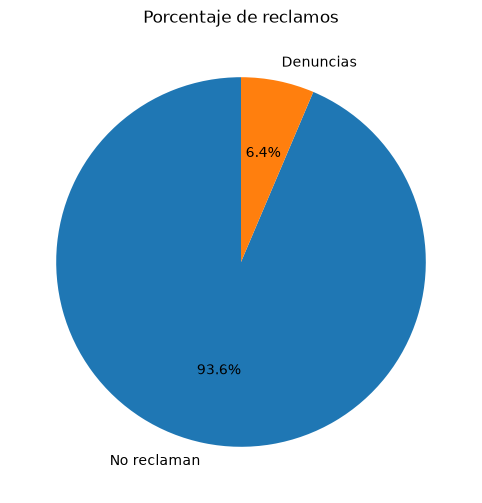

In [17]:
plt.figure(figsize=(12,6))
conteo_denuncias = df.is_claim.value_counts()
plt.pie(conteo_denuncias, labels=("No reclaman","Denuncias"), autopct="%1.1f%%", startangle=90)
plt.title("Porcentaje de reclamos")
plt.show()

In [18]:
conteo_denuncias

is_claim
0    54844
1     3748
Name: count, dtype: int64

## Análisis de la variable "antiguedad de vehículos"

In [19]:
# Hipotesis Nro. 1 = 1.	Los vehículos más antiguos, considerados de colección,  presentan una menor tasa de reclamos? 
# Los propietarios de estos vehículos suelen utilizarlos solo para encuentros o exposiciones.

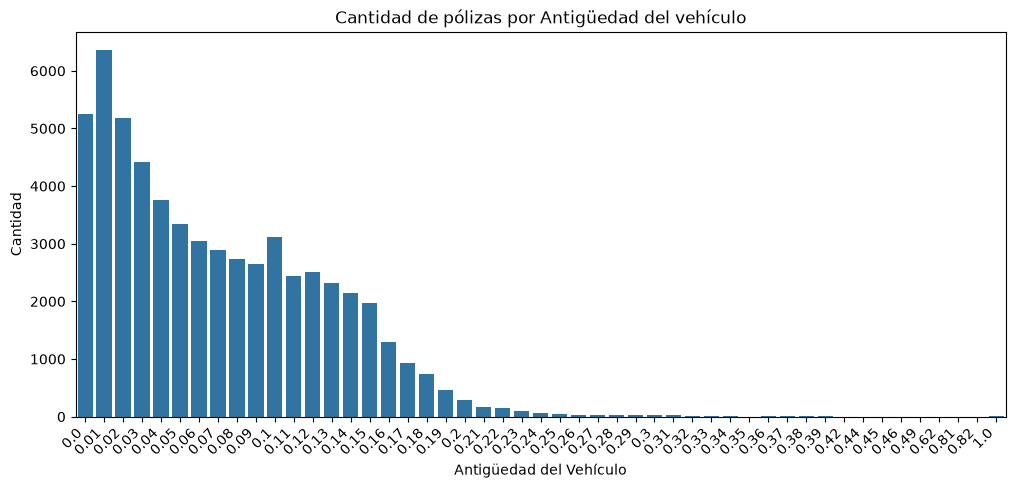

In [20]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="age_of_car")
plt.xticks(rotation=45, ha="right")
plt.title("Cantidad de pólizas por Antigüedad del vehículo")
plt.xlabel("Antigüedad del Vehículo")
plt.ylabel("Cantidad")
plt.show()

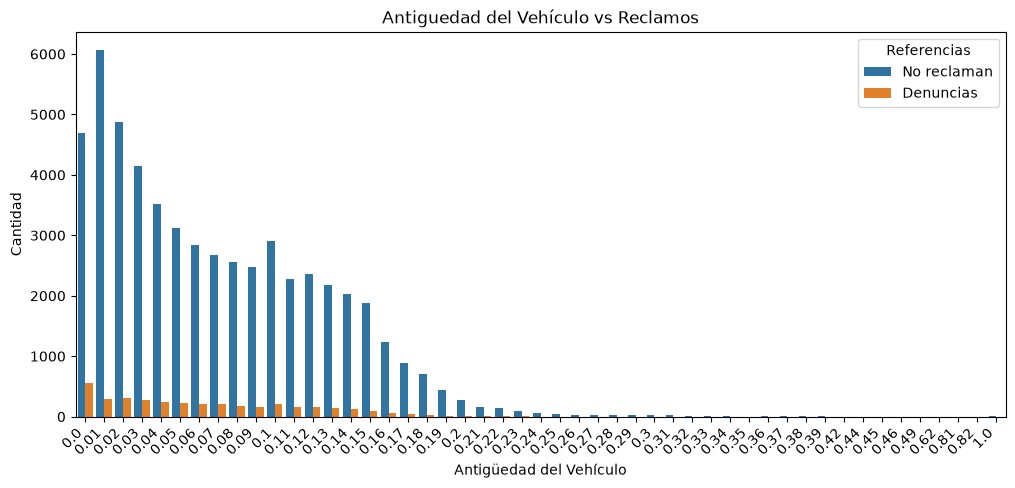

In [21]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="age_of_car", hue="is_claim")
plt.xticks(rotation=45, ha="right")
plt.title("Antiguedad del Vehículo vs Reclamos")
plt.xlabel("Antigüedad del Vehículo")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["No reclaman","Denuncias"], loc="upper right")
plt.show()

In [22]:
# como desconozco el criterio que se utilizó para normalizar la antigüedad de los vehículos en el conjunto de datos, genero 5
# categorías.
# Sin poder precisar años, por lo observado en la gráfica, asumo que los vehículos comprendidos entre los valores 0 y 0,2, pertencen al universo normal de vehículos
# en circulación, (0 km., nuevos y usados), mientras que los que se encuentran por encima del valor 0,2 los considero antiguos (vehículos que podrían catalogarse 
# como de colección). Categorías creadas: "Nuevo", "Semi Nuevo", "Usado", "Antiguo", "Muy Antiguo"

In [23]:
cortes = [0, 0.04, 0.08, 0.2, 0.3, 1]
categoria =["Nuevo", "Semi Nuevo", "Usado", "Antiguo", "Muy Antiguo"]
df["clasif_car"] = pd.cut(df["age_of_car"], bins = cortes, labels = categoria)

In [24]:
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,clasif_car
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,Yes,No,No,No,Yes,0,0,Semi Nuevo
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,Yes,No,No,No,Yes,0,0,Nuevo
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,Yes,No,No,No,Yes,0,0,Nuevo
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0,Usado
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0,Usado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,...,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0,Usado
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,...,No,No,Yes,No,No,No,Yes,0,0,Nuevo
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,...,No,No,Yes,No,No,No,Yes,0,0,Semi Nuevo
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0,Usado


In [25]:
categoria

['Nuevo', 'Semi Nuevo', 'Usado', 'Antiguo', 'Muy Antiguo']

In [26]:
# en base a estas categorías, grafico cantidad de reclamos vs no reclamos

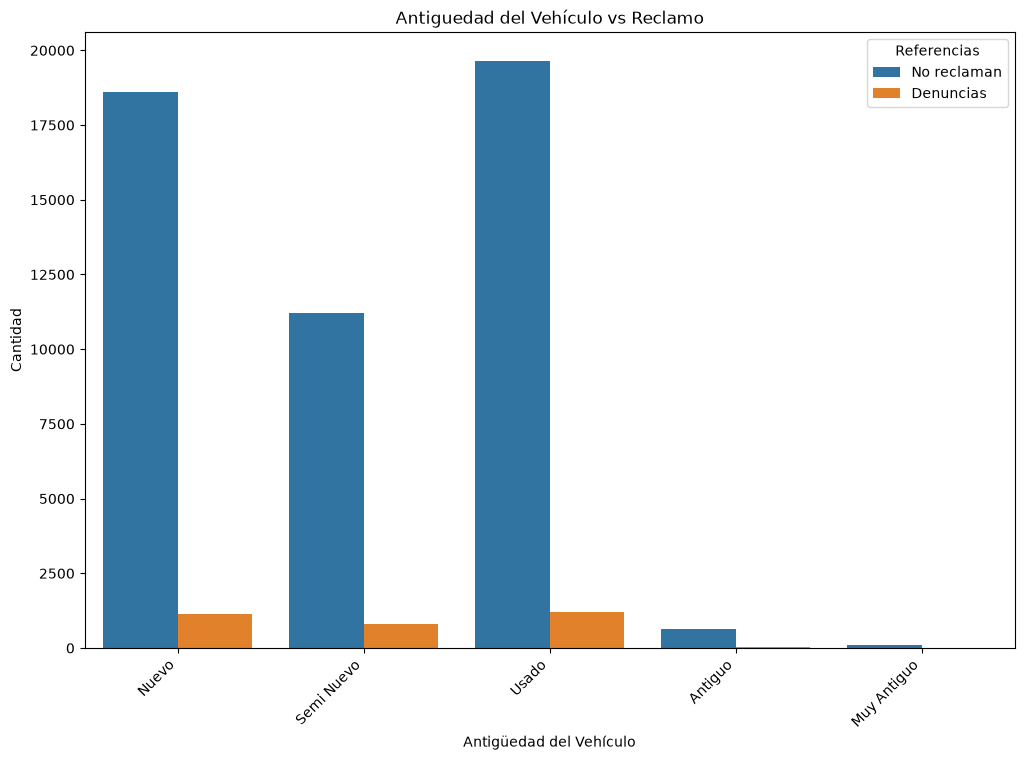

In [27]:
plt.figure(figsize=(12,8))
sns.countplot(data=df, x="clasif_car", hue="is_claim")
plt.xticks(rotation=45, ha="right")
plt.title("Antiguedad del Vehículo vs Reclamo")
plt.xlabel("Antigüedad del Vehículo")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["No reclaman","Denuncias"], loc="upper right")
plt.show()

In [28]:
df.clasif_car.value_counts()

clasif_car
Usado          20849
Nuevo          19729
Semi Nuevo     12013
Antiguo          652
Muy Antiguo       92
Name: count, dtype: int64

In [29]:
df.clasif_car.value_counts(normalize=True)*100

clasif_car
Usado          39.090653
Nuevo          36.990719
Semi Nuevo     22.523671
Antiguo         1.222462
Muy Antiguo     0.172495
Name: proportion, dtype: float64

In [30]:
# Genero la variable "tasa_reclamos_clasif_car", calculando el promedio de reclamos, agrupados por cada clasificación creada.
# Luego genero un gráfico de barras, para comparar los porcentajes de reclamos por cada segmento.

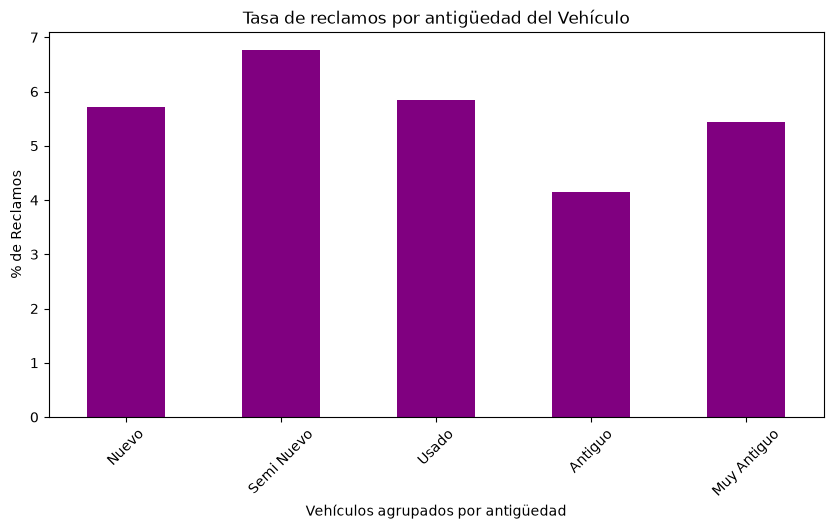

In [31]:
tasa_reclamos_clasif_car = df.groupby("clasif_car")["is_claim"].mean()*100
plt.figure(figsize=(10,5))
tasa_reclamos_clasif_car.plot(kind="bar", color="purple")
plt.xticks(rotation=45)
plt.title("Tasa de reclamos por antigüedad del Vehículo")
plt.xlabel("Vehículos agrupados por antigüedad")
plt.ylabel("% de Reclamos")
plt.show()

In [32]:
tasa_reclamos_clasif_car

clasif_car
Nuevo          5.717472
Semi Nuevo     6.759344
Usado          5.837210
Antiguo        4.141104
Muy Antiguo    5.434783
Name: is_claim, dtype: float64

In [33]:
# llamativamente se observa que el porcentaje de denuncias, por esta clasificación de antigüedad, es muy similar en todas,
# refutando la hipótesis planteada.

In [34]:
# grafico la distribución de pólizas, por antigüedad del vehículo asegurado, discriminando entre los que realizaron denuncia 
# y los que no.

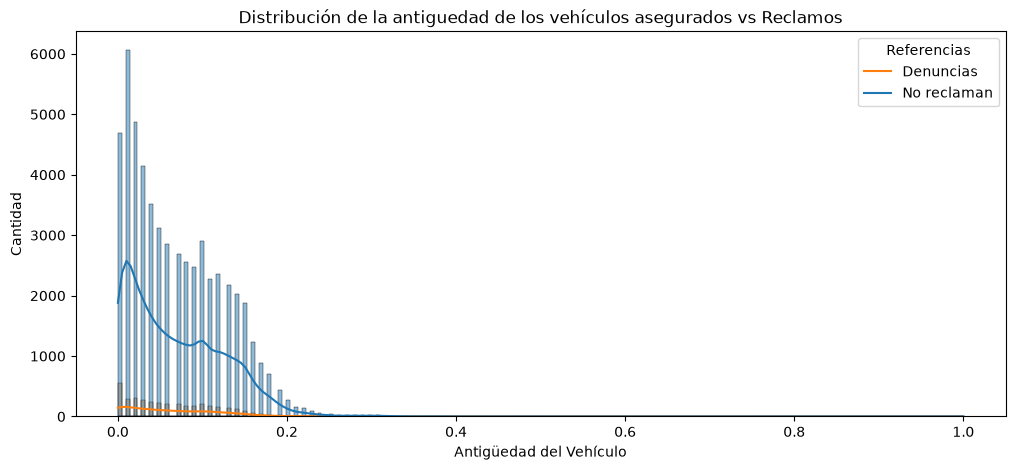

In [35]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="age_of_car", hue="is_claim", kde=True)
plt.title("Distribución de la antiguedad de los vehículos asegurados vs Reclamos")
plt.xlabel("Antigüedad del Vehículo")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclaman"], loc="upper right")
plt.show()

In [36]:
# limito el gráfico entre 0 y 0,2 como para tener mejor apreciación del segmento donde están concentrados la mayoría de los datos

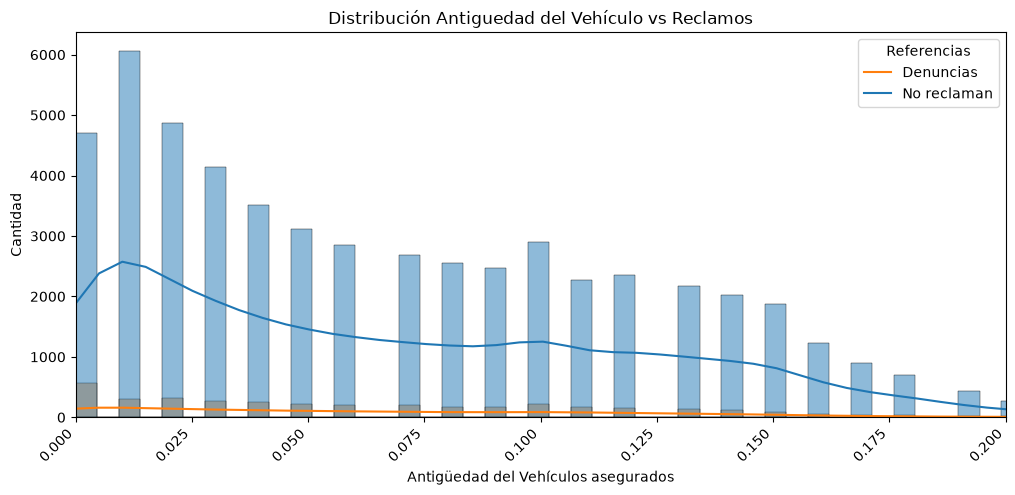

In [37]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="age_of_car", hue="is_claim", kde=True)
plt.xticks(rotation=45, ha="right")
plt.title("Distribución Antiguedad del Vehículo vs Reclamos")
plt.xlabel("Antigüedad del Vehículos asegurados")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclaman"], loc="upper right")
plt.xlim(0,0.2)
plt.show()

In [38]:
# mediante un grafico Boxplot, verifico los valores atípicos, en la antigüedad de los vehículos asegurados. 

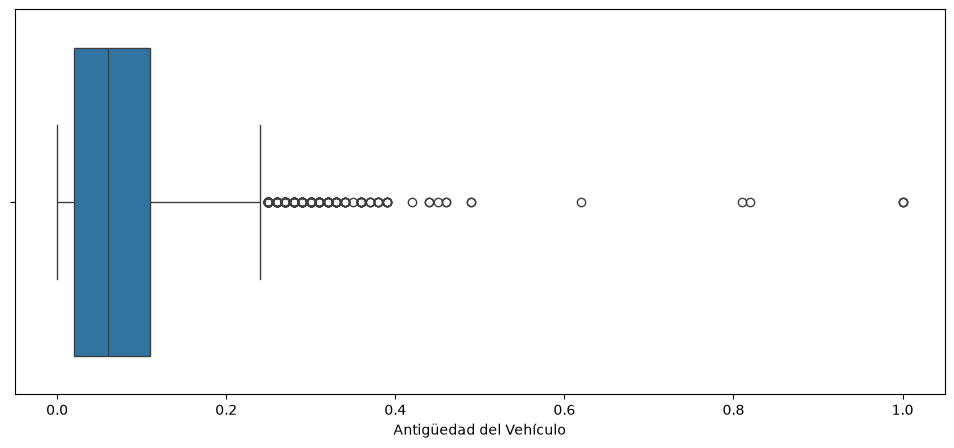

In [39]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="age_of_car")
plt.xlabel("Antigüedad del Vehículo")
plt.show()

In [40]:
df.age_of_car.describe()

count    58592.000000
mean         0.069424
std          0.056721
min          0.000000
25%          0.020000
50%          0.060000
75%          0.110000
max          1.000000
Name: age_of_car, dtype: float64

In [41]:
# calculo el valor exacto del bigote superior del gráfico.

In [42]:
Q1 = 0.02
Q3 = 0.11
IQR = Q3 - Q1
bigote_sup = Q3 + 1.5 * IQR

In [43]:
bigote_sup

0.245

In [44]:
# En los valores normalizados de la antigüedad del vehículo del dataset, los valores atípicos se encuentran a partir de 0,245.
# Genero una función para calcular el bigote superior, y utilizarla en los futuros gráficos bloxplot.

In [45]:
def calculo_bigote_sup(df, col):
    Q1 =  df[col].quantile(0.25)
    Q3 =  df[col].quantile(0.75)
    IQR = Q3 - Q1

    upper_bound = Q3 + 1.5 * IQR
    return upper_bound
    

In [46]:
print("El bigote superior del boxplot es:",calculo_bigote_sup(df, "age_of_car"))

El bigote superior del boxplot es: 0.245


In [47]:
# Evalúo como se comporta la distribución de la variable "Antigüedad del Vehículo", si a los valores atípicos, les asigno el 
# promedio de la variable. 
# Para hacerlo, defino la función (copiada de la clase 9), "tratar_outlaier_iqr"

In [48]:
def tratar_outlier_iqr(df, col):
    Q1 =  df[col].quantile(0.25)
    Q3 =  df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mean_value = df[col].mean()

    df[col + "_sin_outlier"] = df[col].where((df[col] >= lower_bound) & (df[col] <=upper_bound), mean_value)

    return df

In [49]:
df = tratar_outlier_iqr(df,"age_of_car")

In [50]:
df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'make', 'segment', 'model',
       'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags',
       'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim', 'clasif_car',
       'age_of_car_sin_outlier'],
      dtype='str')

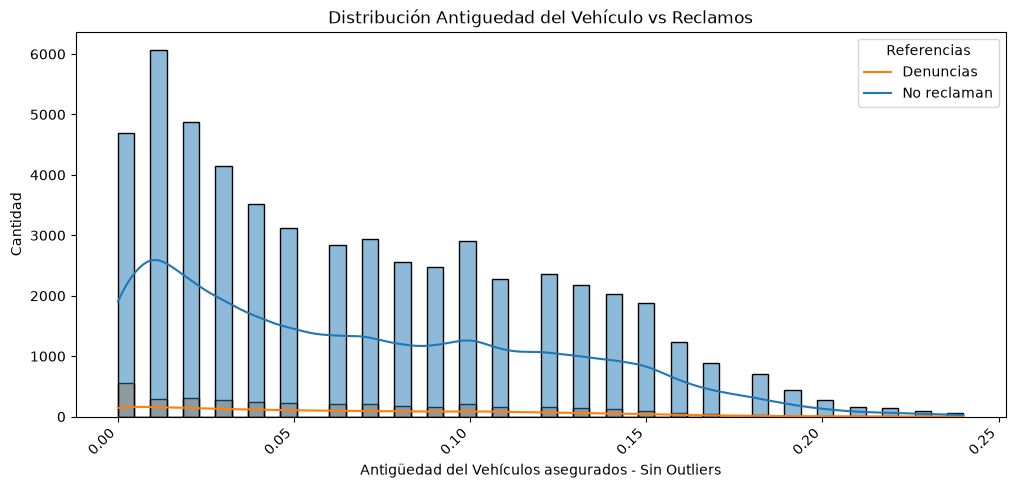

In [51]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="age_of_car_sin_outlier", hue="is_claim", kde=True)
plt.xticks(rotation=45, ha="right")
plt.title("Distribución Antiguedad del Vehículo vs Reclamos")
plt.xlabel("Antigüedad del Vehículos asegurados - Sin Outliers")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclaman"], loc="upper right")
plt.show()

In [52]:
# si bien visualmente se observa que la distribución no es normal, lo corroboro con la librería KS. 

In [53]:
from scipy.stats import kstest, norm

In [54]:
#"""
#h0: la variable es normal
#h1: la variable no es normal

#si p-value > 0.05 -> no rechazamos H0, por ende, "podria ser normal"
#si p-value < 0.05 -> rechazamos h0, por ende, NO ES NORMAL

#"""

In [55]:
data = df["age_of_car_sin_outlier"]
data_std = (data-data.mean())/ (data.std())

In [56]:
stat, p_value = kstest(data_std,"norm")

In [57]:
stat

np.float64(0.12674255696604197)

In [58]:
p_value

np.float64(0.0)

In [59]:
# como p_value es menor que 0,5 refuto la hipótesis nula. Puedo asegurar que la variable no tiene una distribución normal. 

## Análisis de la variable "edad de los asegurados"

In [60]:
# Hipótesis Nro. 2 = La tasa de siniestros, esta relacionada con la edad del asegurado?

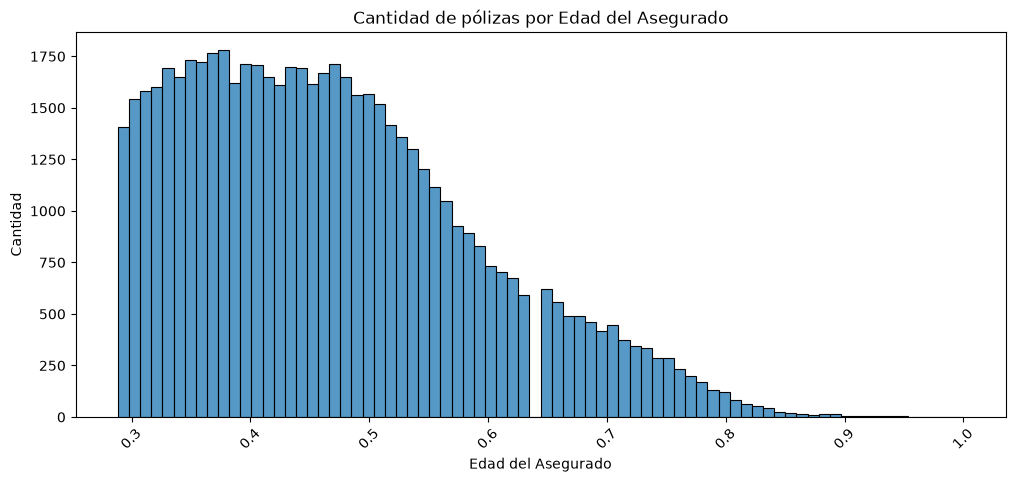

In [61]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="age_of_policyholder")
plt.title("Cantidad de pólizas por Edad del Asegurado")
plt.xlabel("Edad del Asegurado")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.show()

In [62]:
df.age_of_policyholder.describe()

count    58592.000000
mean         0.469420
std          0.122886
min          0.288462
25%          0.365385
50%          0.451923
75%          0.548077
max          1.000000
Name: age_of_policyholder, dtype: float64

In [63]:
# grafico su distribución, diferenciando entre "Denuncias" y "No reclamo"

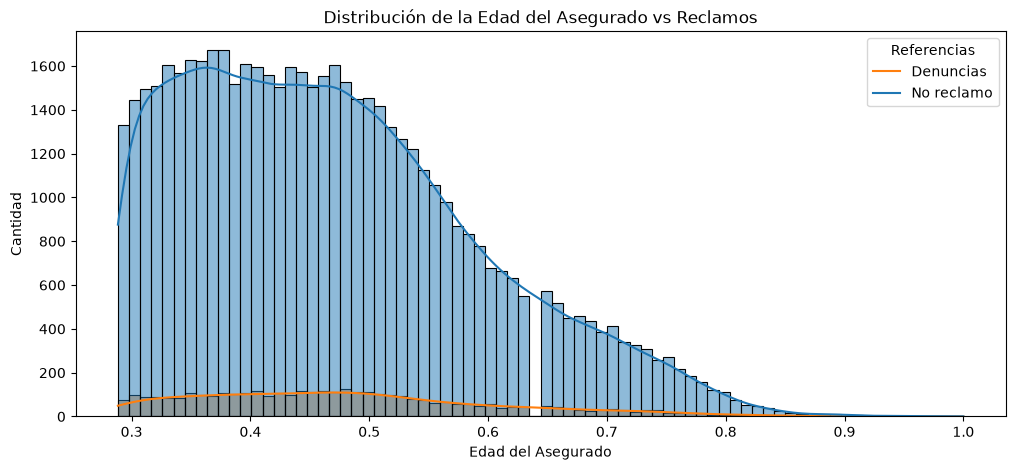

In [64]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="age_of_policyholder", hue="is_claim", kde=True)
plt.title("Distribución de la Edad del Asegurado vs Reclamos")
plt.xlabel("Edad del Asegurado")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclamo"], loc="upper right")
plt.show()

In [65]:
# Suponiendo que el menor valor de la variable (min  0.288462), pertenece a la edad a partir de la cual un individuo 
# es mayor de edad (18 años), pudiendo contratar una póliza a su nombre, asumiendo que la variable Edad comienza de cero,
# y que haya sido normalizada a traves de una funcion lineal (Edad = pendiente * age_of_policyholder ) -> Pendiente = Edad / age_of_policyholder
# el valor máximo de la variable (max  1.000000) correspondería a una edad de 62 años.
# A continuación justifico este planteo, con los cálculos.

In [66]:
Pendiente = 18 / 0.288462

In [67]:
Pendiente

62.399900160159746

In [68]:
edad_max = Pendiente * df["age_of_policyholder"].max()

In [69]:
edad_max

np.float64(62.399900160159746)

In [70]:
# A partir de estos cálculos, genero rangos etarios agrupando a los titulares de pólizas, en franjas de 5 años.

In [71]:
rango_a = 25 / Pendiente
rango_b = 30 / Pendiente
rango_c = 35 / Pendiente
rango_d = 40 / Pendiente
rango_e = 45 / Pendiente
rango_f = 50 / Pendiente
rango_g = 55 / Pendiente
rango_h = 60 / Pendiente
rango_i = 65 / Pendiente

In [72]:
rango_a , rango_b , rango_c , rango_d , rango_e , rango_f , rango_g , rango_h , rango_i 

(0.4006416666666667,
 0.48077,
 0.5608983333333333,
 0.6410266666666666,
 0.721155,
 0.8012833333333333,
 0.8814116666666666,
 0.96154,
 1.0416683333333332)

In [73]:
rango_etario = [0, rango_a, rango_b, rango_c, rango_d, rango_e, rango_f, rango_g, rango_h, rango_i]
franja =["18 a 25", "25 a 30", "30 a 35", "35 a 40", "40 a 45", "45 a 50", "50 a 55", "55 a 60", "60 a 65"]
df["rango_etario"] = pd.cut(df["age_of_policyholder"], bins = rango_etario, labels = franja)

In [74]:
df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'make', 'segment', 'model',
       'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags',
       'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim', 'clasif_car',
       'age_of_car_sin_outlier', 'rango_etario'],
      dtype='str')

In [75]:
df.rango_etario.unique()

['40 a 45', '18 a 25', '25 a 30', '35 a 40', '30 a 35', '55 a 60', '45 a 50', '50 a 55', '60 a 65']
Categories (9, str): ['18 a 25' < '25 a 30' < '30 a 35' < '35 a 40' ... '45 a 50' < '50 a 55' < '55 a 60' < '60 a 65']

In [76]:
# Genero la variable "tasa_reclamos_edad_agrup", calculando el promedio de reclamos, agrupados por cada clasificación creada.
# Luego genero un gráfico de barras, para comparar los porcentajes de reclamos por cada franja etaria.

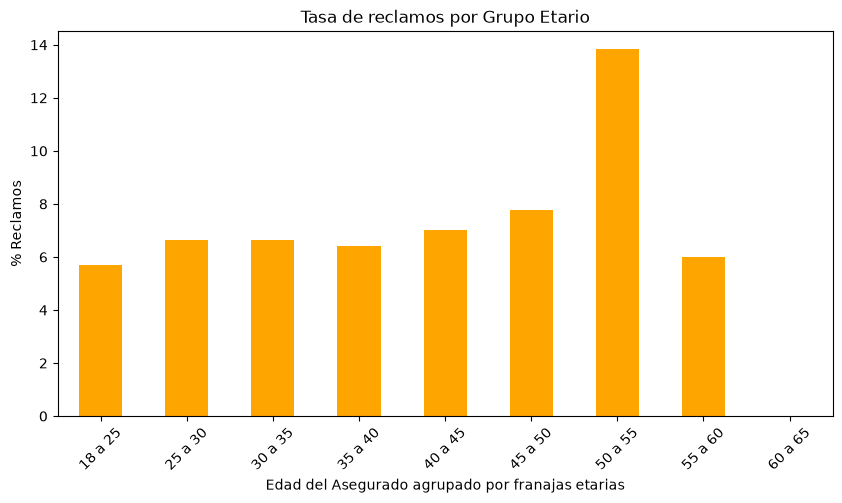

In [77]:
tasa_reclamos_edad_agrup = df.groupby("rango_etario")["is_claim"].mean()*100
plt.figure(figsize=(10,5))
tasa_reclamos_edad_agrup.plot(kind='bar', color = "Orange")
plt.title("Tasa de reclamos por Grupo Etario")
plt.xticks(rotation=45)
plt.xlabel("Edad del Asegurado agrupado por franajas etarias")
plt.ylabel("% Reclamos")
plt.show()

In [78]:
# Con esta gráfica, y de acuerdo a la segmentación realizada de la variable "age_of_policyholder", puede observarse que 
# la franja comprendida entre los 50 y 55 años, practicamente duplica en porcentaje de denuncias, a las demás franjas etarias.
# Con lo que podemos aceptar la hipótesis planteada, ya que en el conjunto de datos analizado, son muchos  menos los 
# asegurados mayores de 50 años, pero el porcentaje de reclamos, es alto respecto a las demas categorías de edad.

In [79]:
df.rango_etario.value_counts()

rango_etario
18 a 25    19814
25 a 30    15008
30 a 35    11047
35 a 40     6399
40 a 45     4198
45 a 50     1761
50 a 55      311
55 a 60       50
60 a 65        4
Name: count, dtype: int64

In [80]:
tasa_reclamos_edad_agrup = df.groupby("rango_etario")["is_claim"].mean()*100
print(tasa_reclamos_edad_agrup)

rango_etario
18 a 25     5.703038
25 a 30     6.629797
30 a 35     6.644338
35 a 40     6.422879
40 a 45     7.027156
45 a 50     7.779671
50 a 55    13.826367
55 a 60     6.000000
60 a 65     0.000000
Name: is_claim, dtype: float64


In [81]:
# Genero un gráfico Boxplot, para visualizar valores atípicos. Si bien observando el conteo de asegurados por edad, se espera
# que los atípicos esten a partir de los 50 años (0.801 en adelante para los valores normalizados de edad).

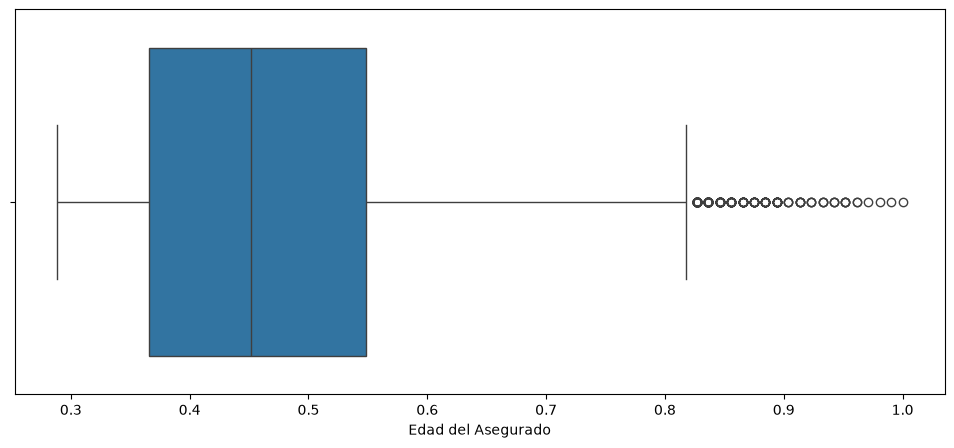

In [82]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="age_of_policyholder")
plt.xlabel("Edad del Asegurado")
plt.show()

In [83]:
# calculo el valor exacto del bigote superior del gráfico, mediante la función generada anteriormente.

In [84]:
print("El bigote superior del boxplot es:",calculo_bigote_sup(df, "age_of_policyholder"))

El bigote superior del boxplot es: 0.822115384615385


In [85]:
Edad_eq = Pendiente * calculo_bigote_sup(df, "age_of_policyholder")

In [86]:
print("La edad equivalente al valor del bigote superior del gráfico es:",Edad_eq)

La edad equivalente al valor del bigote superior del gráfico es: 51.29991792013136


In [87]:
# Si bien la distribución de la variable, observada en los gráficos predecesores, no tiene simetría, igualmente verifico su 
# normalidad con la librería KS.

In [88]:
data = df["age_of_policyholder"]
data_std = (data-data.mean())/ (data.std())

In [89]:
stat, p_value = kstest(data_std,"norm")

In [90]:
stat

np.float64(0.07109311240071786)

In [91]:
p_value

np.float64(5.887898964436239e-258)

In [92]:
# A continuación, realizo un gráfico de dispersión, vinculando las dos variables previamente analizadas, en función de los 
# reclamos.

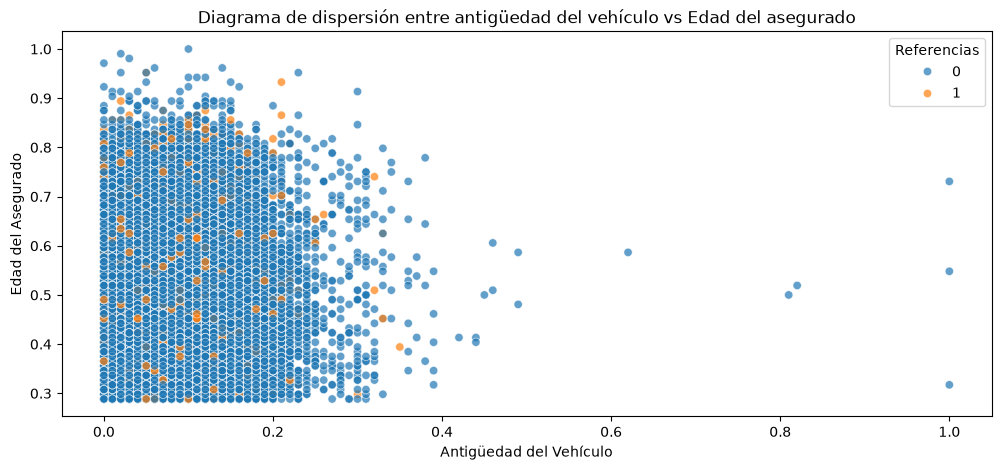

In [93]:
plt.figure(figsize=(12,5))
sns.scatterplot(data=df, x="age_of_car", y="age_of_policyholder", hue = "is_claim", alpha=0.7)
plt.title("Diagrama de dispersión entre antigüedad del vehículo vs Edad del asegurado")
plt.xlabel("Antigüedad del Vehículo")
plt.ylabel("Edad del Asegurado")
plt.legend(title="Referencias")
plt.show()

## Análisis basado en la zona de residencia de los asegurados

In [94]:
# Hipotesis Nro. 3 = En las zonas mas pobladas (con mayor densidad poblacional), el índice de reclamos es mayor?

In [95]:
# Genero la variable "tasa_reclamos_cluster", calculando el promedio de reclamos, agrupados por cada zona geográfica.
# La ordeno de mayor a menor para ver la zona de mayor porcentaje de reclamos a la izquierda del gráfico.

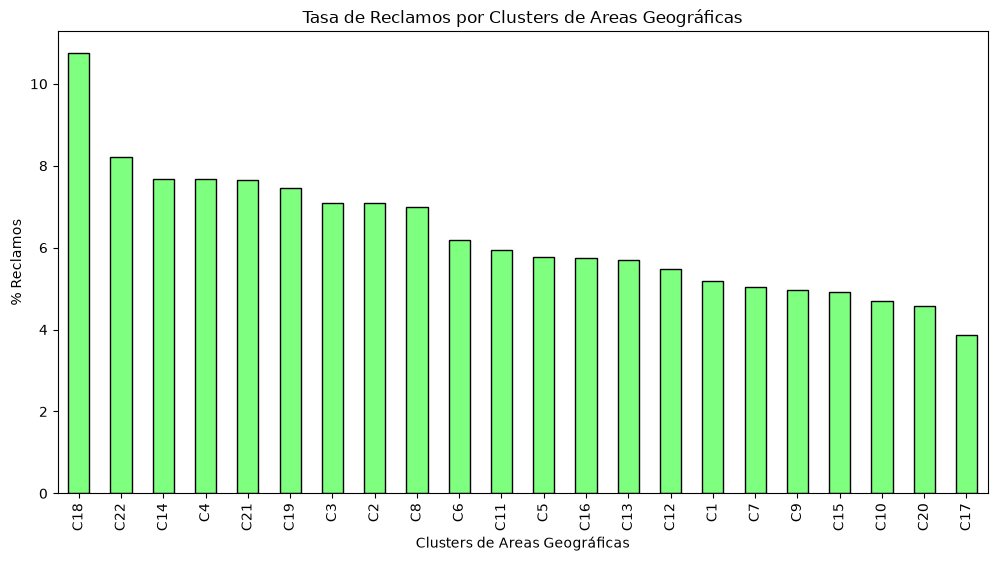

In [96]:
tasa_reclamos_cluster = df.groupby("area_cluster")["is_claim"].mean()*100
tasa_reclamos_cluster_ordenada = tasa_reclamos_cluster.sort_values(ascending=False)
plt.figure(figsize=(12,6))
tasa_reclamos_cluster_ordenada.plot(kind='bar', color = "#00FF0080", edgecolor="Black")
plt.title("Tasa de Reclamos por Clusters de Areas Geográficas")
plt.xlabel("Clusters de Areas Geográficas")
plt.ylabel("% Reclamos")
plt.show()

In [97]:
# Notando que el cluster C18, contiene el mayor porcentaje de reclamos.
# Entonces grafico la cantidad de pólizas por cada región, diferenciando entre "No Reclamos" y "Denuncias"como para analizar 
# si el cluster C18 es significativo.

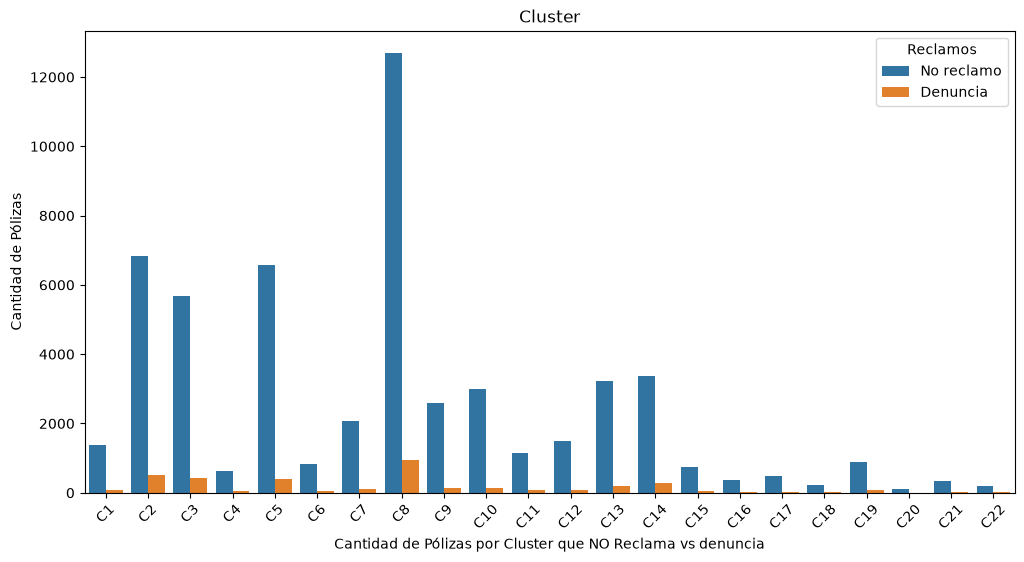

In [98]:
plt.figure(figsize=(12,6))
sns.countplot(data=df, x="area_cluster", hue="is_claim")
plt.title("Cluster")
plt.xticks(rotation=45)
plt.xlabel("Cantidad de Pólizas por Cluster que NO Reclama vs denuncia")
plt.ylabel("Cantidad de Pólizas")
plt.legend(title="Reclamos", labels=["No reclamo", "Denuncia"])
plt.show()

In [99]:
df.area_cluster.value_counts()

area_cluster
C8     13654
C2      7342
C5      6979
C3      6101
C14     3660
C13     3423
C10     3155
C9      2734
C7      2167
C12     1589
C1      1468
C11     1212
C19      952
C6       890
C15      771
C4       665
C17      492
C16      401
C21      379
C18      242
C22      207
C20      109
Name: count, dtype: int64

In [100]:
# verifico la densidad poblacional de cada cluster, vinculandolos con la variable "population_density"

In [101]:
df.groupby("area_cluster")["population_density"].unique()

area_cluster
C1      [4990]
C10    [73430]
C11     [6108]
C12    [34791]
C13     [5410]
C14     [7788]
C15      [290]
C16    [16206]
C17    [65567]
C18    [35036]
C19    [27742]
C2     [27003]
C20    [20905]
C21     [3264]
C22    [16733]
C3      [4076]
C4     [21622]
C5     [34738]
C6     [13051]
C7      [6112]
C8      [8794]
C9     [17804]
Name: population_density, dtype: object

In [102]:
# Observando que el cluster C10 es el de mayor densidad poblacional, con un valor de 73430
# Como vimos en el gráfico de "Tasa de Reclamos por Clusters de Areas Geográficas", tiene un porcentaje de denuncias
# relativamente bajo al resto (exactamente 4.69 %) 

In [103]:
tasa_reclamos_cluster = df.groupby("area_cluster")["is_claim"].mean()*100
print(tasa_reclamos_cluster)

area_cluster
C1      5.177112
C10     4.690967
C11     5.940594
C12     5.475142
C13     5.696757
C14     7.677596
C15     4.928664
C16     5.735661
C17     3.861789
C18    10.743802
C19     7.457983
C2      7.082539
C20     4.587156
C21     7.651715
C22     8.212560
C3      7.097197
C4      7.669173
C5      5.774466
C6      6.179775
C7      5.029995
C8      6.986964
C9      4.974396
Name: is_claim, dtype: float64


In [104]:
# Verifico la distribución de la variable Cluster Area.

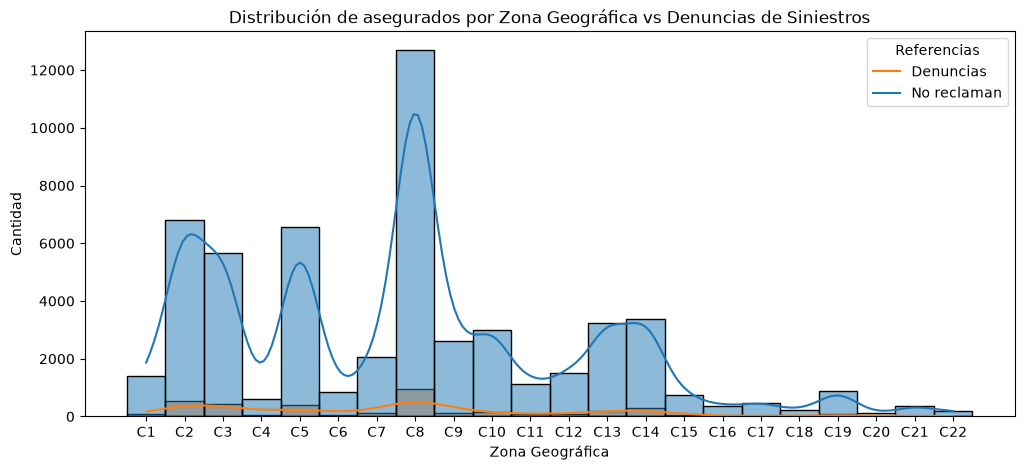

In [105]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="area_cluster", hue="is_claim", kde=True)
plt.title("Distribución de asegurados por Zona Geográfica vs Denuncias de Siniestros")
plt.xlabel("Zona Geográfica")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclaman"], loc="upper right")
plt.show()

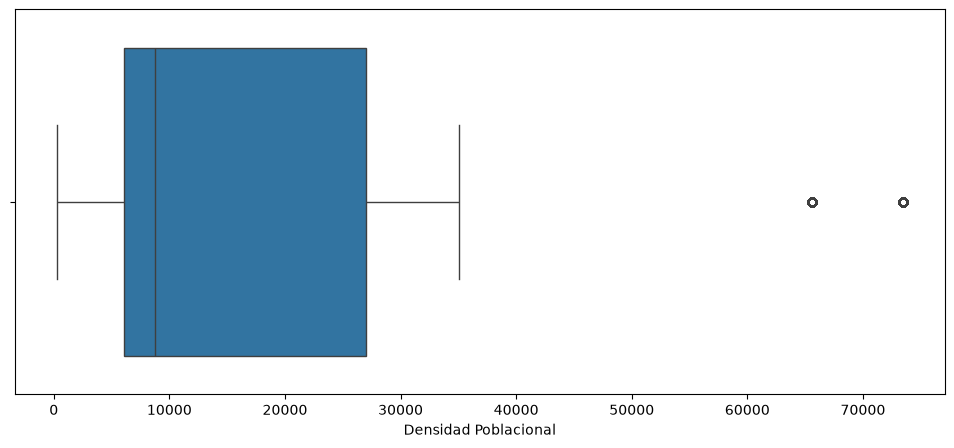

In [106]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="population_density")
plt.xlabel("Densidad Poblacional")
plt.show()

In [107]:
print("El bigote superior del boxplot es:",calculo_bigote_sup(df, "population_density"))

El bigote superior del boxplot es: 58339.5


### Por qué no lo grafica correctamente?, porque la variable no es continua?

In [108]:
Q1 = 6112
Q3 = 27003
IQR = Q3 - Q1
bigote_sup_Dens = Q3 + (1.5 * IQR)

In [109]:
bigote_sup_Dens

58339.5

In [110]:
df.population_density.describe()

count    58592.000000
mean     18826.858667
std      17660.174792
min        290.000000
25%       6112.000000
50%       8794.000000
75%      27003.000000
max      73430.000000
Name: population_density, dtype: float64

In [111]:
# se refuta la hipótesis 3, ya que del análisis de los datos, no puedo aseverar que en las áreas con mayor 
# densidad poblacional, hay una tasa de reclamos mayor.

### Análisis relacionado a la antiguedad de las pólizas

In [112]:
# Hipotesis Nro. 4 = La antigüedad del asegurado en la compañía, influye sobre los reclamos?

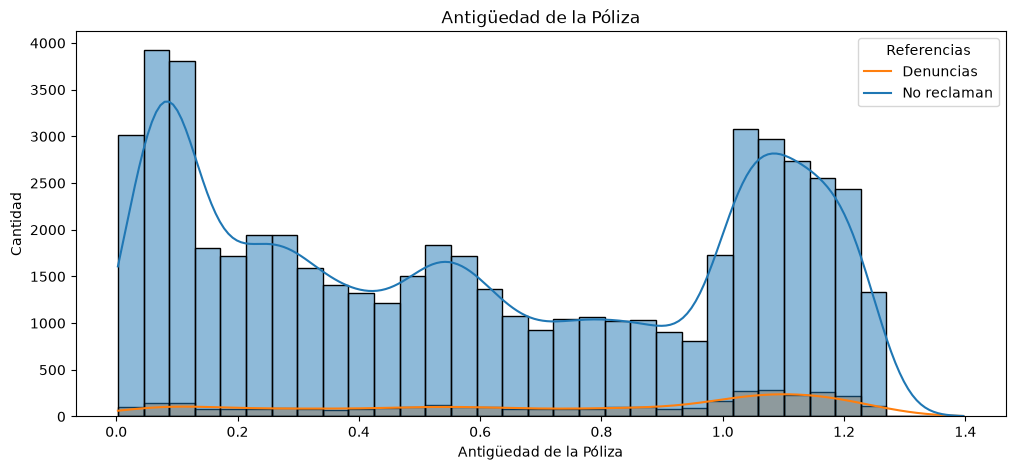

In [113]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="policy_tenure", hue="is_claim", kde=True)
plt.title("Antigüedad de la Póliza")
plt.xlabel("Antigüedad de la Póliza")
plt.ylabel("Cantidad")
plt.legend(title="Referencias", labels=["Denuncias","No reclaman"], loc="upper right")
plt.show()

In [114]:
#plt.figure(figsize=(8, 5))
#sns.boxplot(data=df, x='is_claim', y='policy_tenure')
#plt.title('Comparación de Policy Tenure por Estado de Reclamo')
#plt.xlabel('¿Hizo un Reclamo? (0 = No, 1 = Sí)')
#plt.ylabel('Años de la Póliza')
#plt.show()

In [115]:
df.policy_tenure.nunique()

58592

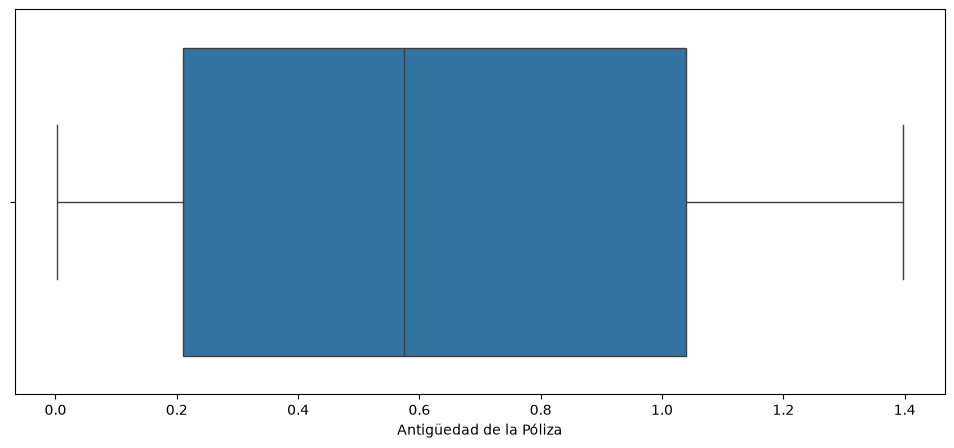

In [116]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="policy_tenure")
plt.xlabel("Antigüedad de la Póliza")
plt.show()

In [117]:
df.policy_tenure.describe()

count    58592.000000
mean         0.611246
std          0.414156
min          0.002735
25%          0.210250
50%          0.573792
75%          1.039104
max          1.396641
Name: policy_tenure, dtype: float64

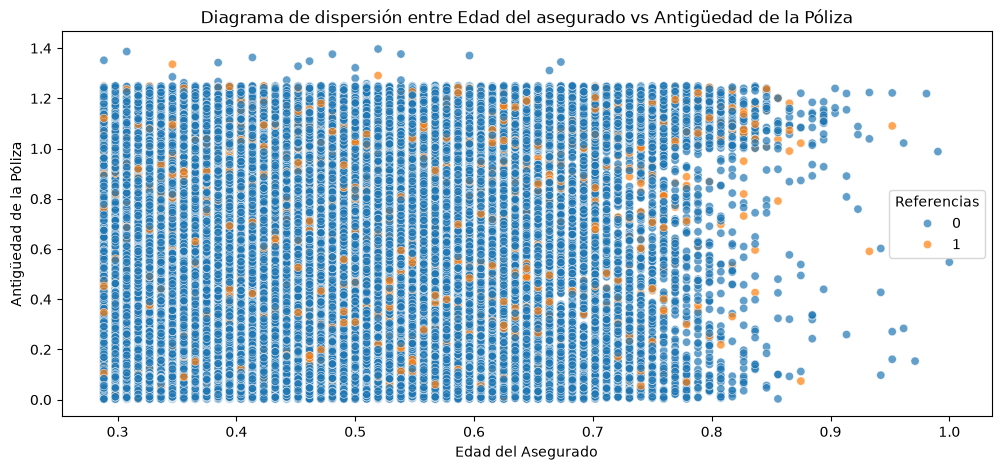

In [118]:
plt.figure(figsize=(12,5))
sns.scatterplot(data=df, x="age_of_policyholder", y="policy_tenure", hue = "is_claim", alpha=0.7)
plt.title("Diagrama de dispersión entre Edad del asegurado vs Antigüedad de la Póliza")
plt.xlabel("Edad del Asegurado")
plt.ylabel("Antigüedad de la Póliza")
plt.legend(title="Referencias")
plt.show()

In [119]:
data = df["age_of_policyholder"]
data_std = (data-data.mean())/ (data.std())

In [120]:
stat, p_value = kstest(data_std,"norm")

In [121]:
p_value

np.float64(5.887898964436239e-258)

## Análisis relacionado a las características mecánicas y de seguridad de los vehículos

In [122]:
# Hipótesis Nro. 5 = Los vehículos mas grandes generan mayor cantidad de siniestros?
# Hipótesis Nro. 6 = Los autos con motores mas potentes, generan mas siniestros?
# Hipótesis Nro. 7 = Los vehículos equipados con sistemas de seguridad, presentan menos tasa de reclamos?

In [123]:
# Genero la variable volúmen vehículo, para tener una magnitud del tamaño. Tratando a los mismos como si fueran prismas rectangulares.

In [124]:
df["volumen_vehiculo"] = df["length"] * df["width"] * df["height"]

In [125]:
df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'make', 'segment', 'model',
       'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags',
       'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim', 'clasif_car',
       'age_of_car_sin_outlier', 'rango_etario', 'volumen_vehiculo'],
      dtype='str')

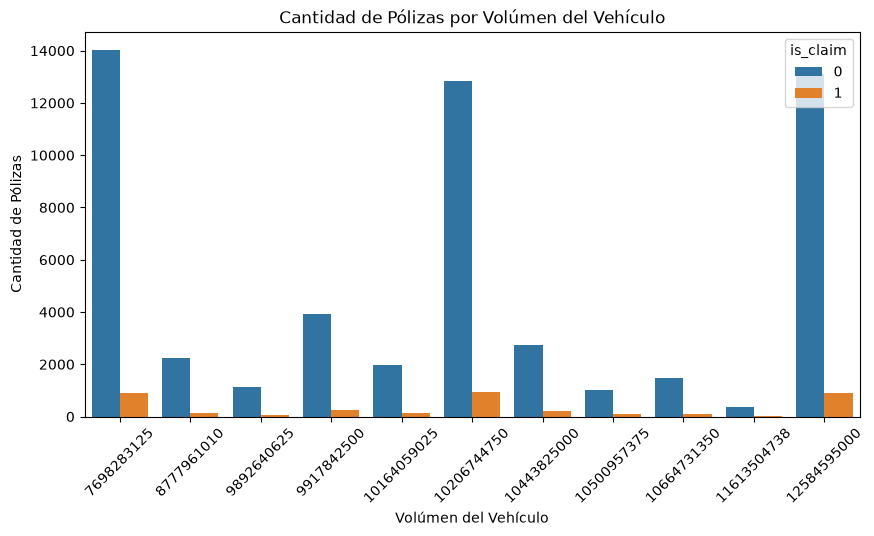

In [126]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="volumen_vehiculo", hue="is_claim")
plt.title("Cantidad de Pólizas por Volúmen del Vehículo")
plt.xlabel("Volúmen del Vehículo")
plt.ylabel("Cantidad de Pólizas")
plt.xticks(rotation=45)
plt.show()

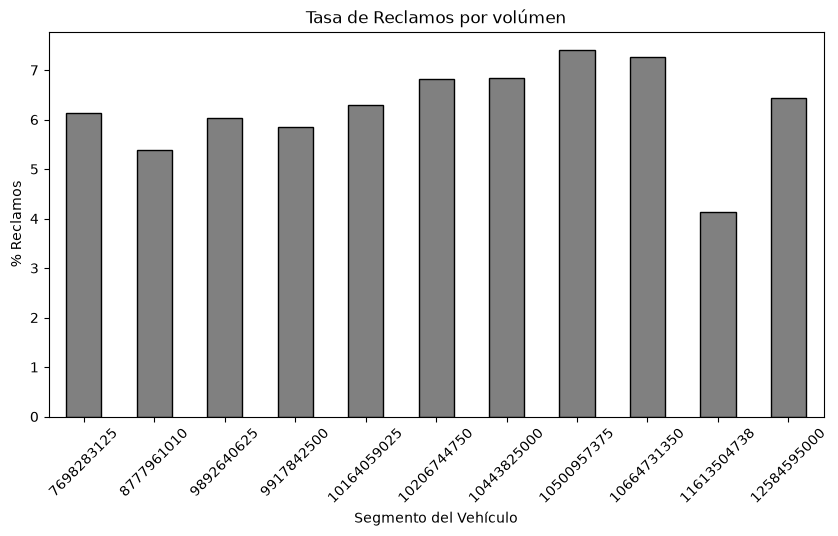

In [127]:
tasa_reclamo_volumen = (df.groupby("volumen_vehiculo")["is_claim"].mean()*100)
plt.figure(figsize=(10,5))
tasa_reclamo_volumen.plot(kind="bar", color = "grey", edgecolor="Black")
plt.title("Tasa de Reclamos por volúmen")
plt.xticks(rotation=45)
plt.xlabel("Segmento del Vehículo")
plt.ylabel("% Reclamos")
plt.show()

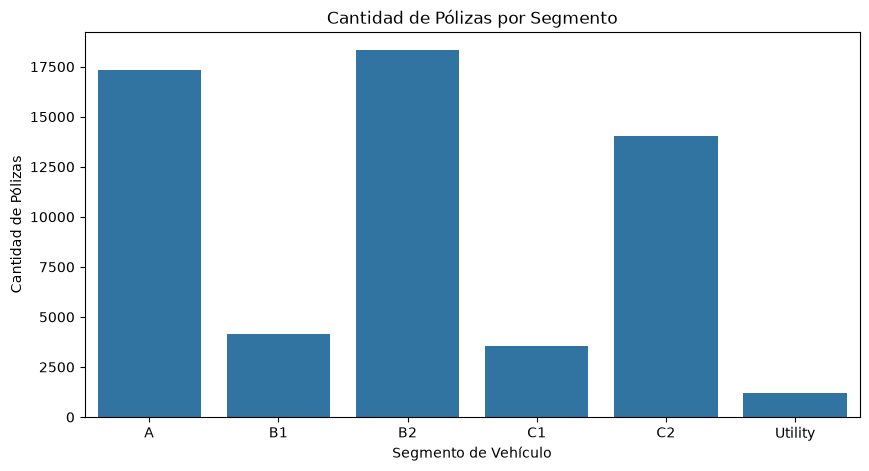

In [128]:
# Genero un gráfico para visualizar la cantidad de pólizas contratadas, de acuerdo al segmento de cada vehículo.
# Ordeno el eje de las X alfabéticamente, por segmentos.
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="segment", order=sorted(set(df.segment)))
plt.title("Cantidad de Pólizas por Segmento")
plt.xlabel("Segmento de Vehículo")
plt.ylabel("Cantidad de Pólizas")
plt.show()

In [129]:
df.segment.value_counts()

segment
B2         18314
A          17321
C2         14018
B1          4173
C1          3557
Utility     1209
Name: count, dtype: int64

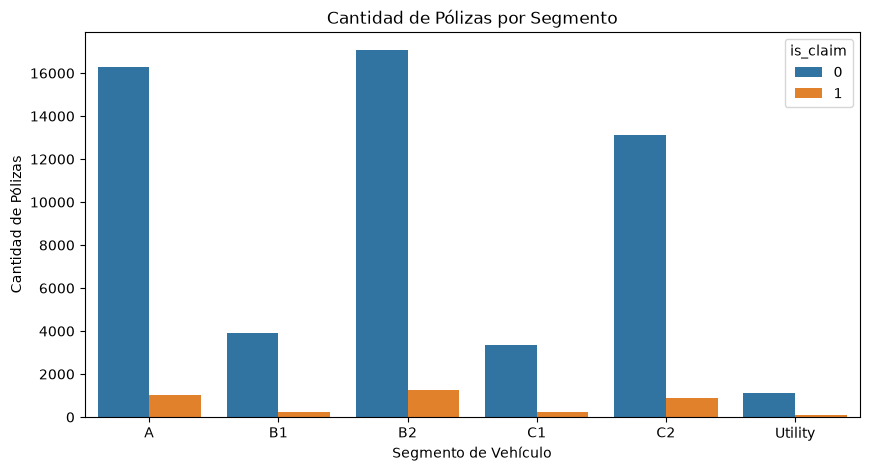

In [130]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="segment", hue="is_claim", order=sorted(set(df.segment)))
plt.title("Cantidad de Pólizas por Segmento")
plt.xlabel("Segmento de Vehículo")
plt.ylabel("Cantidad de Pólizas")
plt.show()

In [131]:
no_reclamo = (df.groupby("segment")["is_claim"].count())

In [132]:
no_reclamo

segment
A          17321
B1          4173
B2         18314
C1          3557
C2         14018
Utility     1209
Name: is_claim, dtype: int64

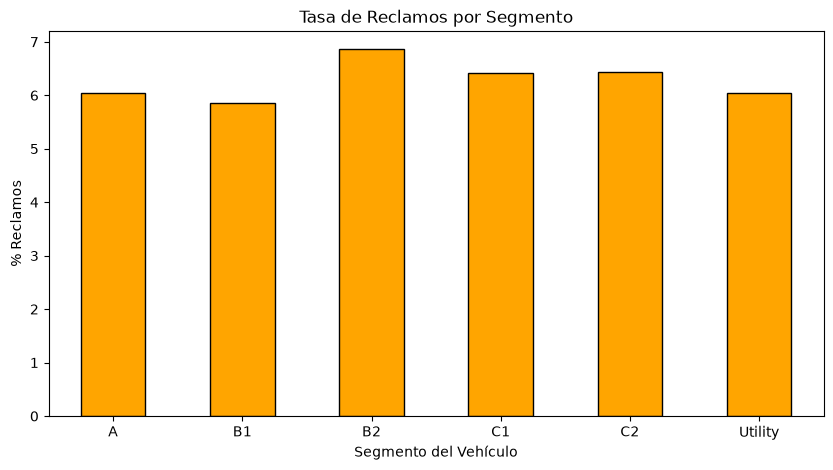

In [133]:
segment_claim = (df.groupby("segment")["is_claim"].mean()*100)
plt.figure(figsize=(10,5))
segment_claim.plot(kind="bar", color = "Orange", edgecolor="Black")
plt.title("Tasa de Reclamos por Segmento")
plt.xticks(rotation=0)
plt.xlabel("Segmento del Vehículo")
plt.ylabel("% Reclamos")
plt.show()

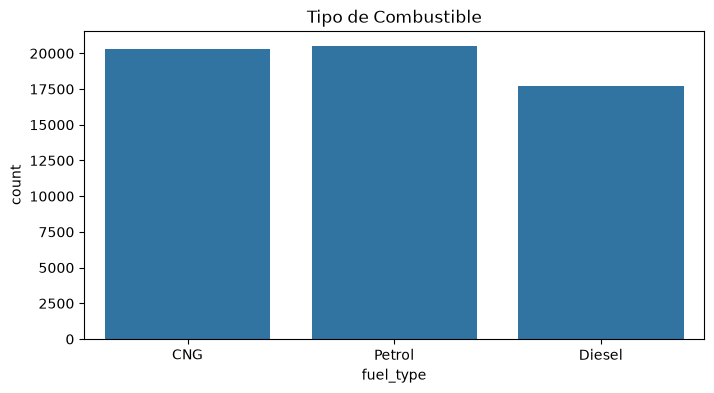

In [134]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='fuel_type')
plt.title('Tipo de Combustible')
plt.show()


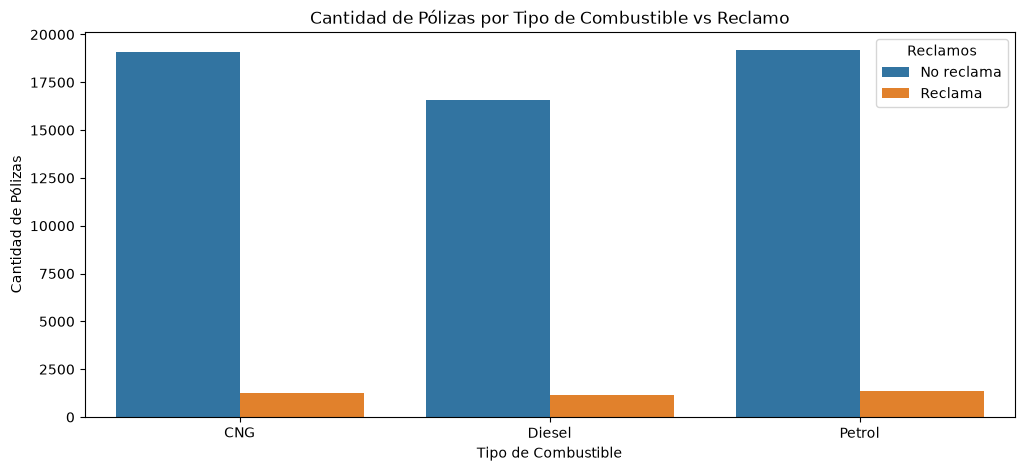

In [135]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="fuel_type", hue="is_claim", order=sorted(set(df.fuel_type)))
plt.title("Cantidad de Pólizas por Tipo de Combustible vs Reclamo")
plt.xlabel("Tipo de Combustible")
plt.ylabel("Cantidad de Pólizas")
plt.legend(title="Reclamos", labels=["No reclama", "Reclama"])
plt.show()

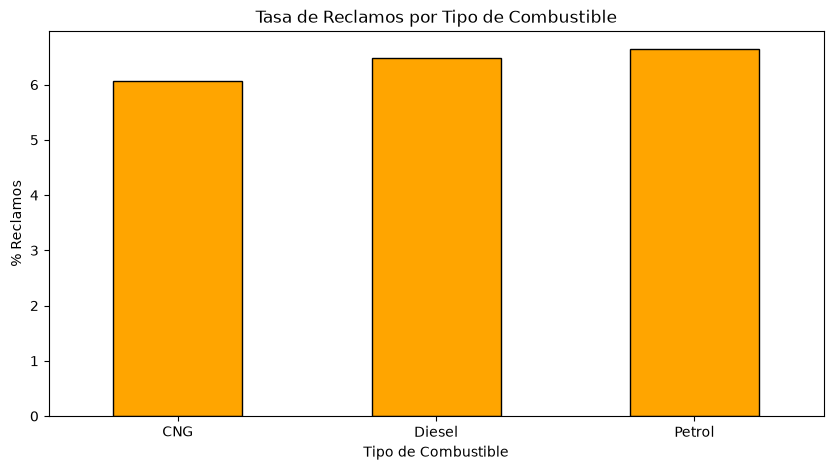

In [136]:
fuel_claim = (df.groupby("fuel_type")["is_claim"].mean()*100)
plt.figure(figsize=(10,5))
fuel_claim.plot(kind="bar", color = "Orange", edgecolor="Black")
plt.title("Tasa de Reclamos por Tipo de Combustible")
plt.xticks(rotation=0)
plt.xlabel("Tipo de Combustible")
plt.ylabel("% Reclamos")
plt.show()

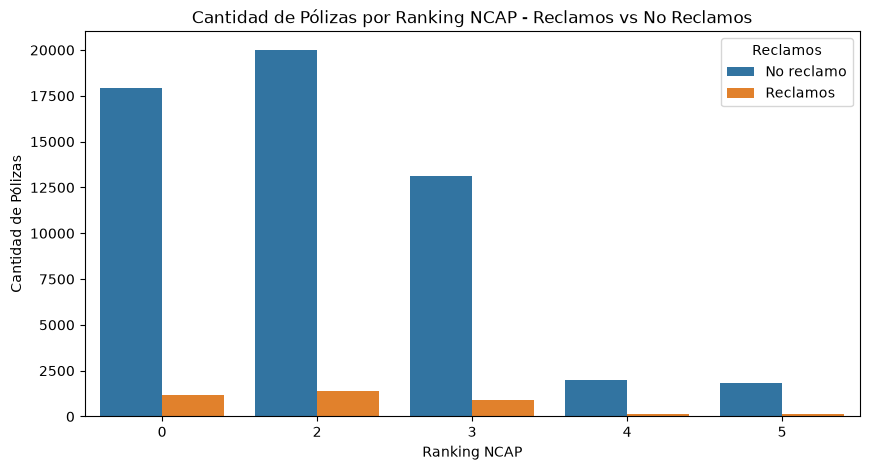

In [137]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="ncap_rating", hue="is_claim", order=sorted(set(df.ncap_rating)))
plt.title("Cantidad de Pólizas por Ranking NCAP - Reclamos vs No Reclamos")
plt.xlabel("Ranking NCAP")
plt.ylabel("Cantidad de Pólizas")
plt.legend(title="Reclamos", labels=["No reclamo", "Reclamos"])
plt.show()

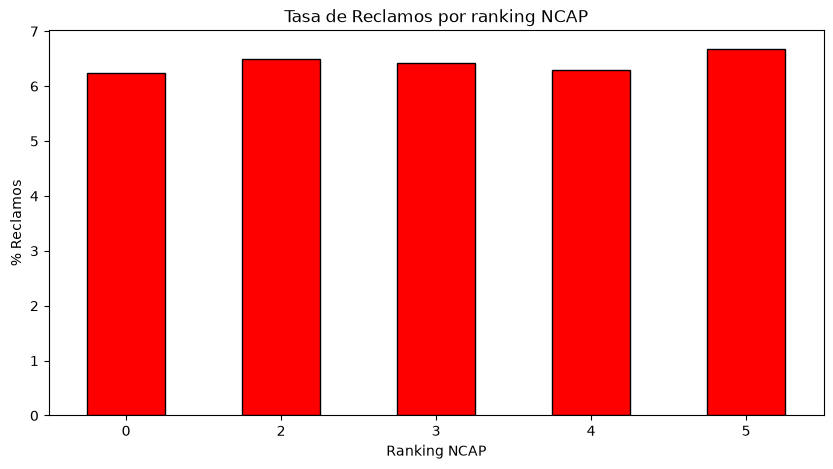

In [138]:
ncap_claim = (df.groupby("ncap_rating")["is_claim"].mean()*100)
plt.figure(figsize=(10,5))
ncap_claim.plot(kind="bar", color = "red", edgecolor="Black")
plt.title("Tasa de Reclamos por ranking NCAP")
plt.xticks(rotation=0)
plt.xlabel("Ranking NCAP")
plt.ylabel("% Reclamos")
plt.show()

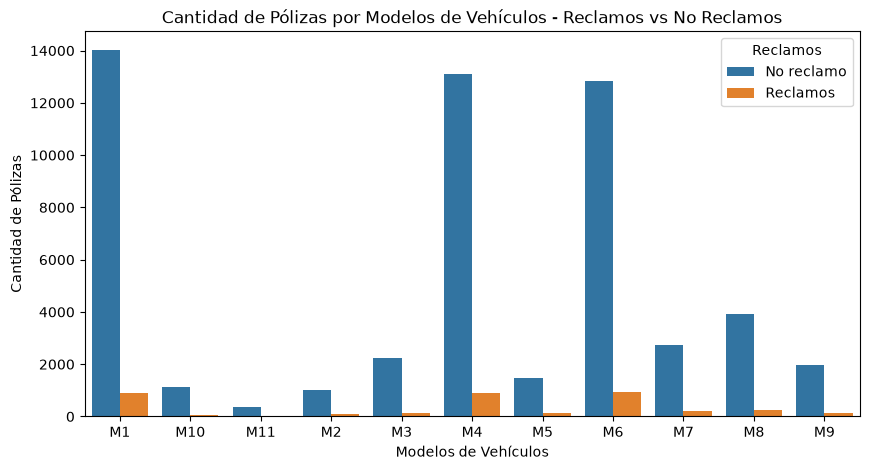

In [139]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="model", hue="is_claim", order=sorted(set(df.model)))
plt.title("Cantidad de Pólizas por Modelos de Vehículos - Reclamos vs No Reclamos")
plt.xlabel("Modelos de Vehículos")
plt.ylabel("Cantidad de Pólizas")
plt.legend(title="Reclamos", labels=["No reclamo", "Reclamos"])
plt.show()

In [140]:
df.max_power.unique()

<ArrowStringArray>
[ '40.36bhp@6000rpm',  '88.50bhp@6000rpm',  '67.06bhp@5500rpm',
 '113.45bhp@4000rpm',  '88.77bhp@4000rpm',  '55.92bhp@5300rpm',
  '97.89bhp@3600rpm',  '61.68bhp@6000rpm', '118.36bhp@5500rpm']
Length: 9, dtype: str

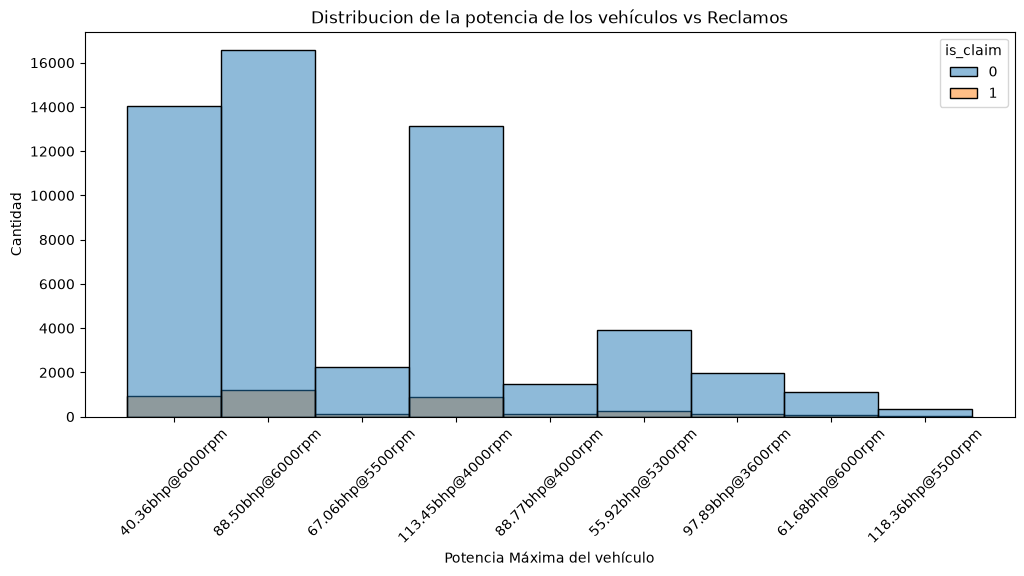

In [141]:
plt.figure(figsize=(12,5))
sns.histplot(data=df, x="max_power", hue="is_claim", discrete = True) #, kde=True)
plt.xticks(rotation=45)
plt.title("Distribucion de la potencia de los vehículos vs Reclamos")
plt.xlabel("Potencia Máxima del vehículo")
plt.ylabel("Cantidad")
plt.show()

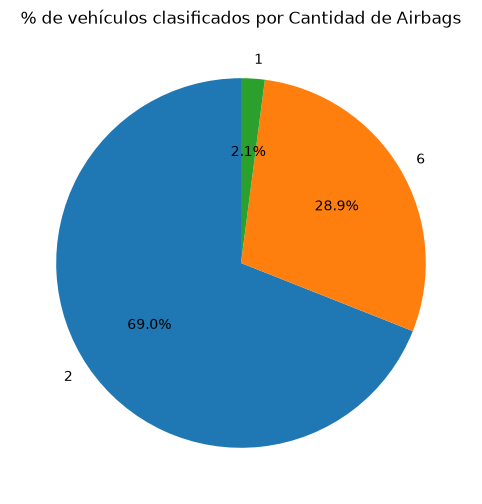

In [142]:
# veo que porcentaje de autos tienen 1 o mas airbags
plt.figure(figsize=(8,6))
airbags = df.airbags.value_counts()
plt.pie(airbags, labels=airbags.index, autopct="%1.1f%%", startangle=90)
plt.title("% de vehículos clasificados por Cantidad de Airbags")
plt.show()

In [143]:
# Se descartan las hipótesis 5, 6 y 7, ya que del análisis realizado, no se observa ingerencia en estas variables, sobre la cantidad de denuncias.